# California Housing – Data Understanding

**CRISP-DM:** Business Understanding → Data Understanding

Dieses Notebook begleitet die systematische Untersuchung des California-Housing-Datensatzes im **Data Understanding**.

## 1. Analysefrage als Leitlinie

Aus dem Business Understanding ergibt sich die datenanalytische Fragestellung:

> **Wie gut lässt sich der Median des Immobilienwerts einer Block Group anhand der verfügbaren Merkmale erklären und vorhersagen?**

Die **Zielgröße** ist `median_house_value`.

Im Data Understanding werden die Daten zunächst **untersucht, beschrieben und fachlich eingeordnet**.  
Die Daten werden an dieser Stelle noch **nicht bereinigt oder für die Modellierung verändert**.


## 2. Datensatz einlesen

Verwendet wird die Datei `housing.csv` aus der in der Vorlesung eingesetzten California-Housing-Datensatzfassung.

Die Datei sollte im selben Verzeichnis wie dieses Notebook liegen.

Eine Beobachtung entspricht einer **Census Block Group**. In der Vorlesung wird dafür teilweise vereinfachend der Begriff **Wohngebiet** verwendet.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_housing = pd.read_csv("../_Data/housing.csv")

df_housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Lösungshinweise zum ersten Blick auf die Daten

- Eine **Zeile** beschreibt eine Block Group.
- Die **Zielgröße** ist `median_house_value`.
- Neben geografischen Merkmalen (`longitude`, `latitude`) liegen Informationen zu Wohnungsbestand, Bevölkerung, Haushalten, Einkommen und Küstennähe vor.
- `ocean_proximity` ist kategorial gespeichert.
- Die übrigen Variablen sind numerisch gespeichert.

Bereits fachlich auffällig ist die unterschiedliche Art der Merkmale:

- `median_income` und `median_house_value` beschreiben typische Werte innerhalb einer Block Group.
- `total_rooms`, `total_bedrooms`, `population` und `households` sind Gesamtsummen für unterschiedlich große Block Groups.

Damit ist noch nicht entschieden, welche Merkmale später für die Modellierung verwendet oder verändert werden.


## 3. Struktur des Datensatzes untersuchen

Zunächst werden Anzahl der Beobachtungen und Variablen, die Spaltennamen und die technischen Datentypen untersucht.


In [2]:
# Anzahl der Beobachtungen und Variablen
df_housing.shape

(20640, 10)

In [3]:
# Namen der Variablen
df_housing.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [4]:
# Datentypen und Anzahl vorhandener Werte
df_housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


### Lösungshorizont zur Struktur

Für die verwendete Datensatzfassung ergibt sich:

- **20.640 Beobachtungen**
- **10 Variablen**
- neun numerisch gespeicherte Variablen
- eine kategorial gespeicherte Variable: `ocean_proximity`
- bei `total_bedrooms` sind weniger Werte vorhanden als bei den übrigen Variablen

Damit gibt es bereits einen ersten Hinweis auf **fehlende Werte**.

Wichtig ist die Unterscheidung:

- Der **Python-Datentyp** beschreibt die technische Speicherungicherung.
- Die **fachliche Bedeutung bzw. das Skalenniveau** bestimmt, welche Kennzahlen und Darstellungen sinnvoll sind.


## Fachliche Grundlage: Bedeutung der Variablen

Für die fachliche Interpretation müssen Bedeutung und Einheit der Variablen bekannt sein.  
Die Übersicht wird auf Grundlage der Datensatzdokumentation als Referenz festgehalten.

| Variable | Bedeutung | Einheit / Besonderheit |
|---|---|---|
| `longitude`, `latitude` | geografische Länge / Breite der Block Group | Grad |
| `housing_median_age` | Median des Gebäudealters | Jahre |
| `total_rooms` | Gesamtzahl der Räume | Anzahl |
| `total_bedrooms` | Gesamtzahl der Schlafzimmer | Anzahl |
| `population` | Bevölkerung | Personen |
| `households` | Anzahl der Haushalte | Anzahl |
| `median_income` | Median des Haushaltseinkommens | skaliertes Einkommensmerkmal |
| `median_house_value` | Median des Immobilienwerts | US-Dollar; Zielgröße |
| `ocean_proximity` | Lage relativ zur Küste | kategorial |

Eine Beobachtung beschreibt eine **Block Group**. Die Merkmale beziehen sich daher auf ein Wohngebiet, nicht auf ein einzelnes Haus.

Einige Merkmale beschreiben typische Werte einer Block Group (`median_income`, `median_house_value`), andere sind Gesamtsummen für unterschiedlich große Block Groups (`total_rooms`, `population`, `households`).


## 4. Datenqualität prüfen

### Vollständigkeit

Fehlende Werte werden systematisch für alle Variablen geprüft.


In [5]:
# Fehlende Werte je Variable
df_housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

### Lösung

In der verwendeten Lehrdatensatzfassung fehlen **207 Werte bei `total_bedrooms`**.

Für die übrigen Variablen werden keine fehlenden Werte angezeigt.

**Wichtig:** Im Data Understanding wird das Problem zunächst nur diagnostiziert.  
Ob und wie die fehlenden Werte ersetzt werden, ist eine Entscheidung der späteren **Data Preparation**.


### Duplikate prüfen

Technisch vollständige Daten sind nicht automatisch eindeutig. Deshalb wird zusätzlich geprüft, ob identische Beobachtungen mehrfach vorkommen.

In [6]:
# Anzahl vollständig doppelter Zeilen
print(df_housing.duplicated().sum())

0


### Einordnung

Für vollständig doppelte Zeilen gilt:

- Ein gefundener Doppelgänger wäre zunächst ein **Hinweis**, kein automatischer Löschauftrag.
- Erst die fachliche Bedeutung der Beobachtung entscheidet, ob es sich tatsächlich um ein Datenproblem handelt.
- Die Behandlung möglicher Duplikate gehört zur **Data Preparation**.


## 5. Technischer Datentyp und fachliches Skalenniveau

Die numerische Speicherung einer Variable bedeutet nicht automatisch, dass sie fachlich wie eine beliebige metrische Größe behandelt werden sollte.

| Variable | Fachliche Einordnung |
|---|---|
| `longitude`, `latitude` | metrische geografische Koordinaten |
| `housing_median_age` | metrisch; Jahre |
| `total_rooms`, `total_bedrooms` | metrisch; diskrete Anzahlen |
| `population`, `households` | metrisch; diskrete Anzahlen |
| `median_income` | metrisch interpretiertes, skaliertes Einkommensmerkmal |
| `median_house_value` | metrische Zielgröße; US-Dollar |
| `ocean_proximity` | nominal / kategorial |

Die fachliche Einordnung wird später benötigt, um geeignete Kennzahlen, Visualisierungen und Aufbereitungsschritte auszuwählen.


In [7]:
# Numerisch und nicht numerisch gespeicherte Variablen
numeric_columns = df_housing.select_dtypes(include="number").columns.tolist()
categorical_columns = df_housing.select_dtypes(exclude="number").columns.tolist()

print("Numerisch gespeichert:", numeric_columns)
print("Nicht numerisch gespeichert:", categorical_columns)

Numerisch gespeichert: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
Nicht numerisch gespeichert: ['ocean_proximity']


## 6. Kategoriale Merkmale untersuchen

Bei kategorialen Merkmalen interessieren zunächst die vorhandenen Ausprägungen und ihre Häufigkeiten.


In [8]:
# Absolute Häufigkeiten
df_housing["ocean_proximity"].value_counts(dropna=False)

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [9]:
# Relative Häufigkeiten
df_housing["ocean_proximity"].value_counts(normalize=True, dropna=False)

ocean_proximity
<1H OCEAN     0.442636
INLAND        0.317393
NEAR OCEAN    0.128779
NEAR BAY      0.110950
ISLAND        0.000242
Name: proportion, dtype: float64

### Lösung

`ocean_proximity` besitzt fünf Ausprägungen:

- `<1H OCEAN`
- `INLAND`
- `NEAR OCEAN`
- `NEAR BAY`
- `ISLAND`

Auffällig ist insbesondere, dass die Kategorien **sehr unterschiedlich häufig** vorkommen und `ISLAND` nur sehr wenige Beobachtungen enthält.

Die Variable ist kategorial. Eine mögliche Codierung wird erst in der **Data Preparation** behandelt.


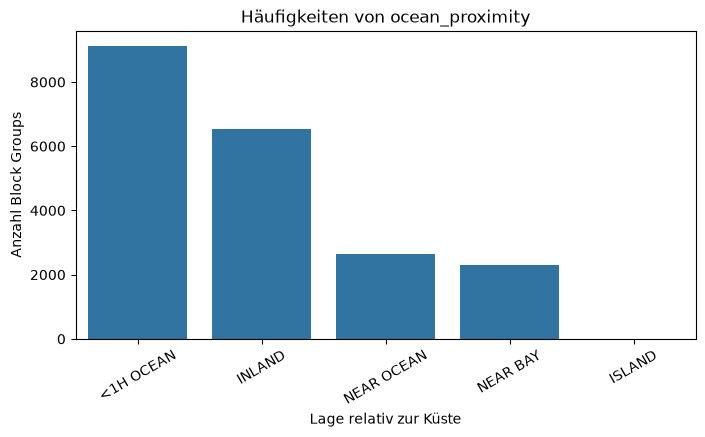

In [10]:
# Häufigkeiten grafisch darstellen
order = df_housing["ocean_proximity"].value_counts().index

plt.figure(figsize=(8, 4))
sns.countplot(data=df_housing, x="ocean_proximity", order=order)
plt.xlabel("Lage relativ zur Küste")
plt.ylabel("Anzahl Block Groups")
plt.title("Häufigkeiten von ocean_proximity")
plt.xticks(rotation=30)
plt.show()

## 7. Plausibilität und auffällige Werte prüfen

Auffällige Werte müssen fachlich beurteilt werden, bevor über ihre Behandlung entschieden wird.

Dabei ist zu unterscheiden:

- **unplausibel:** fachlich nicht sinnvoll oder unmöglich → möglicher Datenfehler
- **auffällig:** ungewöhnlich, aber möglicherweise korrekt
- eine **Häufung exakt an einem Grenzwert** kann auf eine technische Begrenzung des Datensatzes hinweisen

> **Auffällig bedeutet nicht automatisch fehlerhaft. Plausibilität muss fachlich beurteilt werden.**


In [11]:
# Wertebereiche der numerischen Variablen
df_housing[numeric_columns].agg(["min", "max"]).T

,min,max
longitude,-124.3500,-114.3100
latitude,32.5400,41.9500
housing_median_age,1.0000,52.0000
total_rooms,2.0000,39320.0000
total_bedrooms,1.0000,6445.0000
population,3.0000,35682.0000
households,1.0000,6082.0000
median_income,0.4999,15.0001
median_house_value,14999.0000,500001.0000


In [12]:
# Wie häufig treten die beobachteten Maximalwerte auf?
age_max = df_housing["housing_median_age"].max()
value_max = df_housing["median_house_value"].max()
income_max = df_housing["median_income"].max()

print("housing_median_age am Maximum:",
      (df_housing["housing_median_age"] == age_max).sum(),
      "von", len(df_housing))

print("median_house_value am Maximum:",
      (df_housing["median_house_value"] == value_max).sum(),
      "von", len(df_housing))

print("median_income am Maximum:",
      (df_housing["median_income"] == income_max).sum(),
      "von", len(df_housing))

housing_median_age am Maximum: 1273 von 20640
median_house_value am Maximum: 965 von 20640
median_income am Maximum: 49 von 20640


### Einordnung

Die Häufung vieler Beobachtungen **exakt am jeweils beobachteten Maximum** ist auffällig:

- `housing_median_age`: 1.273 Beobachtungen liegen am Maximalwert.
- `median_house_value`: 965 Beobachtungen liegen am Maximalwert.
- `median_income`: 49 Beobachtungen liegen am Maximalwert.

Aus diesen Häufungen allein folgt noch nicht, dass der Maximalwert eine technische Grenze ist. Sie geben aber einen Anlass, die Datensatzdokumentation zu prüfen.

Für die verwendete California-Housing-Lehrdatensatzfassung sind Begrenzungen einzelner Merkmale dokumentiert. Besonders die Begrenzung der Zielgröße `median_house_value` muss später bei Interpretation und Modellbewertung berücksichtigt werden.

Die Werte werden im Data Understanding **nicht verändert**.


## 8. Metrische Merkmale untersuchen

Bei numerischen Merkmalen interessieren Lage, Streuung und Wertebereich.  
`describe()` liefert dafür einen ersten systematischen Überblick.


In [13]:
df_housing.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


### Lösungshorizont zu den Kennzahlen

Aus den Kennzahlen ergeben sich mehrere Hinweise für die weitere Untersuchung:

- Bei `total_bedrooms` ist `count` kleiner als 20.640 – das bestätigt die bereits festgestellten fehlenden Werte.
- Bei `median_house_value` liegt der Mittelwert über dem Median – ein Hinweis auf eine asymmetrische Verteilung.
- Für `housing_median_age`, `median_income` und `median_house_value` fallen markante Maximalwerte auf.
- `total_rooms`, `total_bedrooms`, `population` und `households` besitzen große Wertebereiche; ihre Maximalwerte liegen deutlich über dem 3. Quartil.

Kennzahlen liefern **Hinweise**. Ihre fachliche Einordnung ergibt sich erst aus der Plausibilitätsprüfung, den Verteilungen und – falls erforderlich – der Datensatzdokumentation.


## 9. Verteilungen metrischer Merkmale: Histogramm

Kennwerte fassen eine Verteilung zusammen. Ein Histogramm zeigt ihre **Form**.

Bei `stat="density"` entspricht die Fläche der Balken der relativen Häufigkeit; die Gesamtfläche beträgt 1.  
`kde=True` ergänzt eine geglättete Schätzung der Verteilungsdichte.

### Zielgröße `median_house_value`


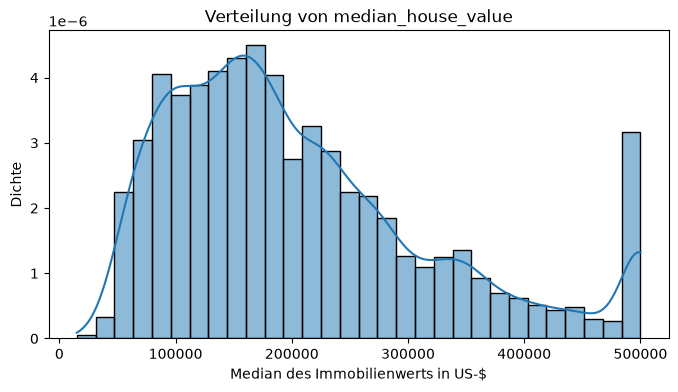

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_housing,
    x="median_house_value",
    bins=30,
    stat="density",
    kde=True
)
plt.xlabel("Median des Immobilienwerts in US-$")
plt.ylabel("Dichte")
plt.title("Verteilung von median_house_value")
plt.show()

### Beobachtungen zur Zielgröße

- Die Verteilung ist nicht symmetrisch.
- Am oberen Ende ist eine deutliche Häufung beim maximal gespeicherten Wert sichtbar.
- Diese Häufung ist mit der in der Datensatzdokumentation beschriebenen Begrenzung der Zielgröße vereinbar.

Die Begrenzung ist für die spätere Interpretation und Modellbewertung relevant.


### Merkmal `median_income`

`median_income` erscheint fachlich besonders interessant, weil Einkommen und Immobilienwerte plausibel zusammenhängen könnten. Zunächst wird das Merkmal einzeln betrachtet.


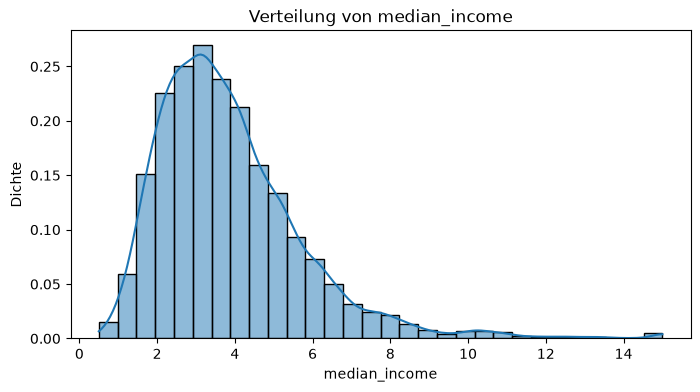

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_housing,
    x="median_income",
    bins=30,
    stat="density",
    kde=True
)
plt.xlabel("median_income")
plt.ylabel("Dichte")
plt.title("Verteilung von median_income")
plt.show()

### Beobachtungen zu `median_income`

- Die Verteilung ist nicht symmetrisch.
- Hohe Werte bilden den rechten Rand der Verteilung.
- Auffällige hohe Werte sind nicht automatisch fehlerhaft.


<small>▶ **Folien 26–27: Boxplot – Verteilungen kompakt beschreiben**</small>


## 10. Boxplot: Verteilungen kompakt beschreiben

Ein Boxplot zeigt Median, Quartile, Streuung und potenzielle Ausreißer kompakt.

**Wichtig:** Ein Punkt außerhalb der Whisker ist nicht automatisch ein fehlerhafter Wert.

### Zielgröße `median_house_value`


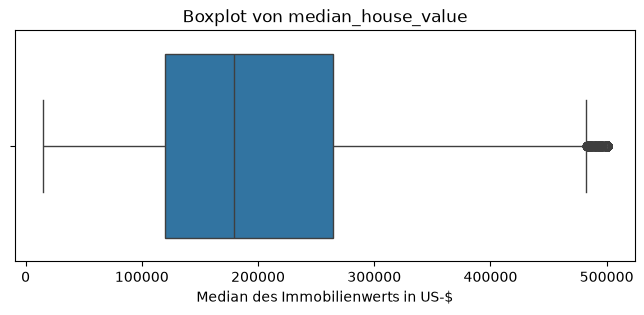

In [16]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=df_housing, x="median_house_value")
plt.xlabel("Median des Immobilienwerts in US-$")
plt.title("Boxplot von median_house_value")
plt.show()

Beim Boxplot der Zielgröße erscheinen hohe Werte als potenzielle Ausreißer. Die bereits erkannte Häufung am maximal gespeicherten Wert ist jedoch durch die Begrenzung der Zielgröße geprägt und darf nicht wie ein gewöhnlicher Ausreißer interpretiert werden.


### Merkmal `median_income`


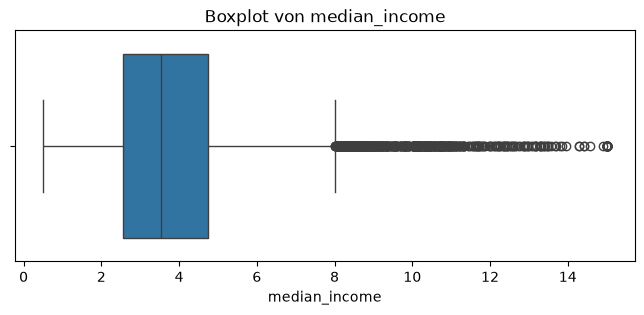

In [17]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=df_housing, x="median_income")
plt.xlabel("median_income")
plt.title("Boxplot von median_income")
plt.show()

Der Boxplot ergänzt das Histogramm:

- Median und Quartile beschreiben die Lage der mittleren Beobachtungen.
- Hohe Werte liegen am rechten Rand der Verteilung und können als potenzielle Ausreißer markiert werden.
- Solche Werte sind zunächst **Analysehinweise**, keine automatischen Löschkandidaten.


<small>▶ **Folien 28–29: Von einzelnen Merkmalen zu Zusammenhängen / Streudiagramm interpretieren**</small>


## 11. Zusammenhang zwischen `median_income` und der Zielgröße

Ein Streudiagramm stellt zwei numerische Merkmale gemeinsam dar. Jede Beobachtung entspricht einem Punkt.

Gesucht werden zunächst **explorative Hinweise** auf

- Richtung und Stärke eines Zusammenhangs,
- besondere Muster,
- auffällige Beobachtungen,
- mögliche Begrenzungseffekte.


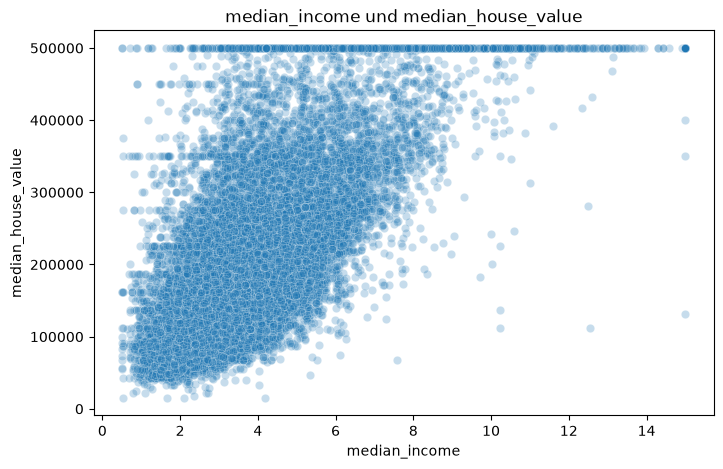

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_housing,
    x="median_income",
    y="median_house_value",
    alpha=0.25
)
plt.xlabel("median_income")
plt.ylabel("median_house_value")
plt.title("median_income und median_house_value")
plt.show()

### Beobachtungen

Im Streudiagramm ist ein **positiver Zusammenhang** erkennbar:

- Block Groups mit höherem `median_income` weisen tendenziell höhere Werte von `median_house_value` auf.
- Die Punkte liegen jedoch nicht auf einer eindeutigen Linie; weitere Merkmale spielen offensichtlich ebenfalls eine Rolle.
- Die horizontale Häufung am oberen Rand der Zielgröße macht deren Begrenzung sichtbar.

Ein sichtbarer Zusammenhang ist **keine Aussage über Kausalität**.


## Weitere Zusammenhänge mit der Zielgröße

Nun werden weitere numerische Merkmale explorativ mit `median_house_value` verglichen.


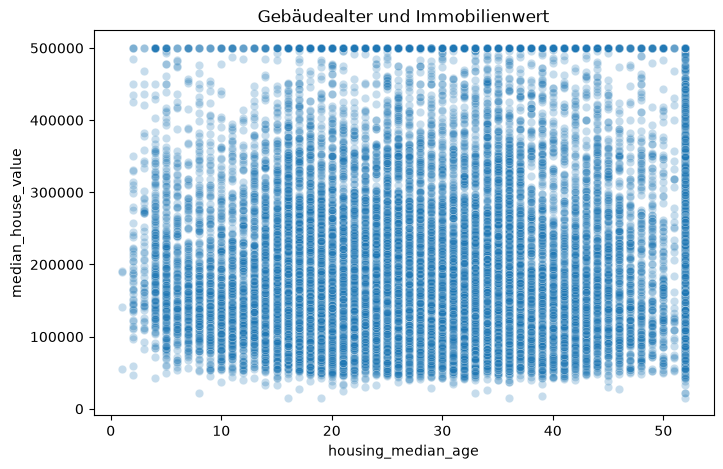

In [19]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_housing,
    x="housing_median_age",
    y="median_house_value",
    alpha=0.25
)
plt.xlabel("housing_median_age")
plt.ylabel("median_house_value")
plt.title("Gebäudealter und Immobilienwert")
plt.show()

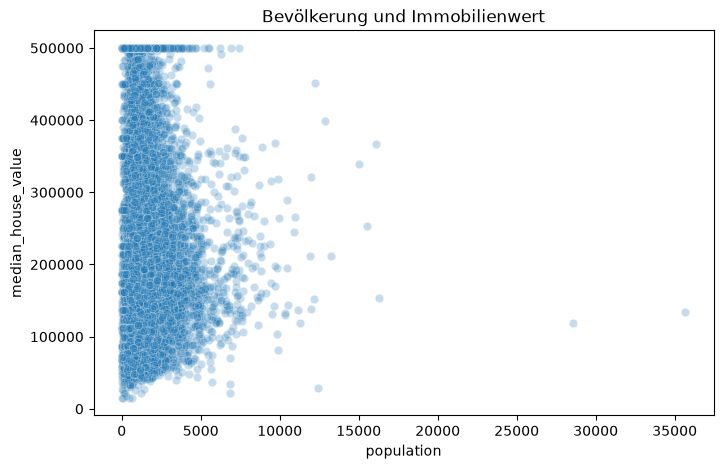

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_housing,
    x="population",
    y="median_house_value",
    alpha=0.25
)
plt.xlabel("population")
plt.ylabel("median_house_value")
plt.title("Bevölkerung und Immobilienwert")
plt.show()

### Einordnung

Die betrachteten Merkmale zeigen deutlich unterschiedliche Muster.

Gerade bei Summenmerkmalen wie `population` ist zu beachten:

- Block Groups unterscheiden sich in ihrer Größe.
- Eine große absolute Bevölkerung bedeutet daher nicht automatisch eine hohe Bevölkerungsdichte.
- Dasselbe Problem betrifft `total_rooms`, `total_bedrooms` und `households`.

Damit entsteht eine fachliche Frage für die spätere Data Preparation:  
**Sind Verhältnisgrößen informativer als reine Gesamtsummen?**


## 12. Korrelationen zwischen numerischen Merkmalen

Die Korrelationsmatrix ergänzt die grafische Exploration quantitativ.

Der Pearson-Korrelationskoeffizient beschreibt **lineare Zusammenhänge** und liegt zwischen −1 und +1:

- nahe +1: starker positiver linearer Zusammenhang
- nahe −1: starker negativer linearer Zusammenhang
- nahe 0: kein oder nur schwacher linearer Zusammenhang

Eine Korrelation beweist weder Kausalität noch endgültige Modellrelevanz.


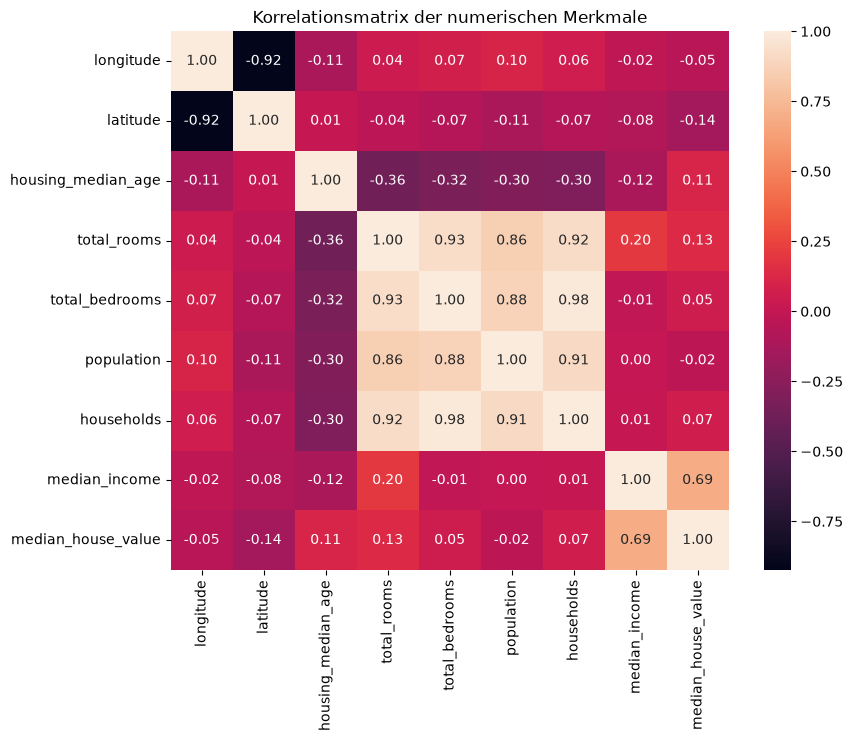

In [21]:
corr = df_housing.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)
plt.title("Korrelationsmatrix der numerischen Merkmale")
plt.show()

In [22]:
# Korrelationen mit der Zielgröße sortieren
corr["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

### Für die Analysefrage besonders interessant

Die Korrelationsmatrix zeigt:

- `median_income` weist unter den vorhandenen numerischen Merkmalen den deutlichsten positiven linearen Zusammenhang mit `median_house_value` auf.
- Für andere einzelne numerische Merkmale sind die linearen Zusammenhänge deutlich schwächer.
- Schwache Pearson-Korrelation bedeutet nicht automatisch, dass ein Merkmal nutzlos ist: nichtlineare Zusammenhänge oder Wechselwirkungen werden damit nicht vollständig erfasst.
- Die geografischen Merkmale sollten zusätzlich räumlich interpretiert werden.

Damit liefert die EDA erste Hinweise darauf, welche Merkmale im weiteren Analyseprozess besonders beachtet werden sollten.


### Räumliche Struktur untersuchen

California Housing enthält mit `longitude` und `latitude` explizite geografische Informationen.  
Ein Streudiagramm der Koordinaten macht die räumliche Struktur des Datensatzes sichtbar.

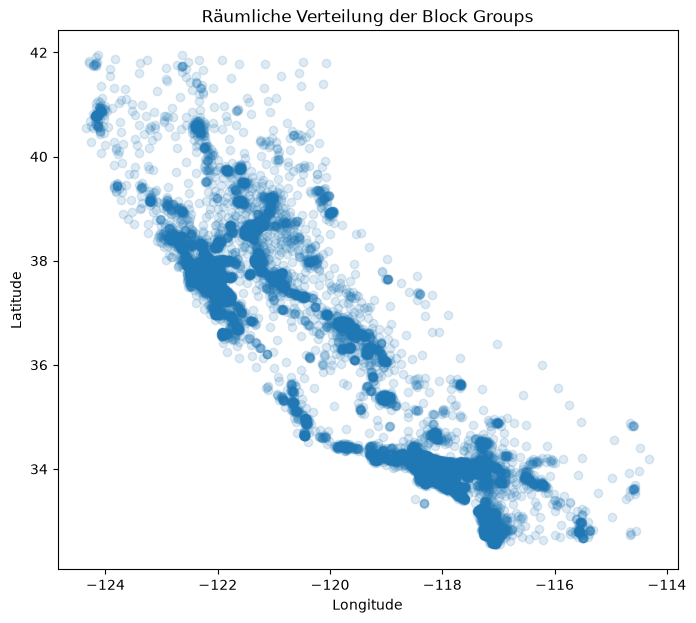

In [23]:
plt.figure(figsize=(8, 7))
plt.scatter(
    df_housing["longitude"],
    df_housing["latitude"],
    alpha=0.15
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Räumliche Verteilung der Block Groups")
plt.show()

Zusätzlich kann die Zielgröße in der räumlichen Darstellung berücksichtigt werden.  
Die Farbe dient hier ausschließlich der explorativen Visualisierung der Immobilienwerte.

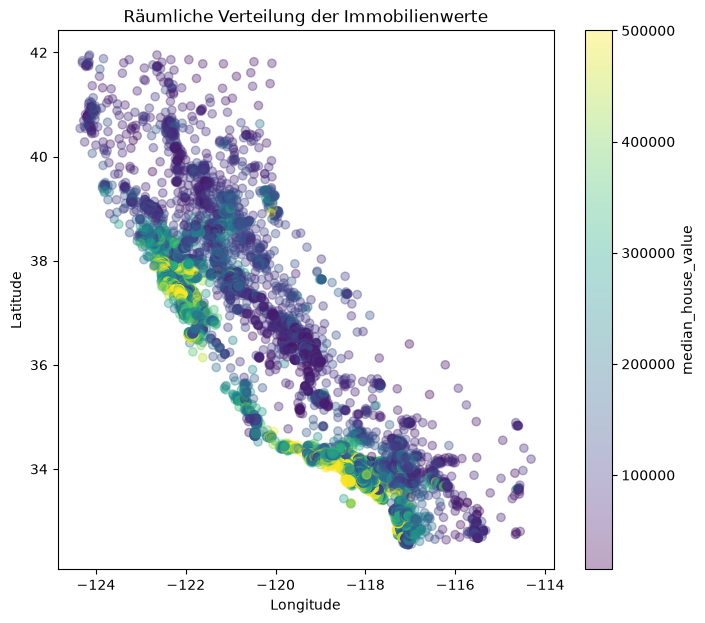

In [24]:
plt.figure(figsize=(8, 7))
scatter = plt.scatter(
    df_housing["longitude"],
    df_housing["latitude"],
    c=df_housing["median_house_value"],
    alpha=0.35
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Räumliche Verteilung der Immobilienwerte")
plt.colorbar(scatter, label="median_house_value")
plt.show()

### Einordnung

Die geografische Lage enthält sichtbar Informationen über die Zielgröße.  
Damit sind `longitude` und `latitude` nicht nur technische Koordinaten, sondern potenziell relevante Merkmale.

Die räumliche Darstellung zeigt außerdem, warum ein rein eindimensionaler Blick auf einzelne Variablen für diesen Datensatz nicht ausreicht.

## 13. Kategoriale und metrische Variablen gemeinsam untersuchen

Auch ein kategoriales Merkmal kann für die Analysefrage relevant sein.  
Mit einem Boxplot werden die Verteilungen von `median_house_value` für die Kategorien von `ocean_proximity` verglichen.


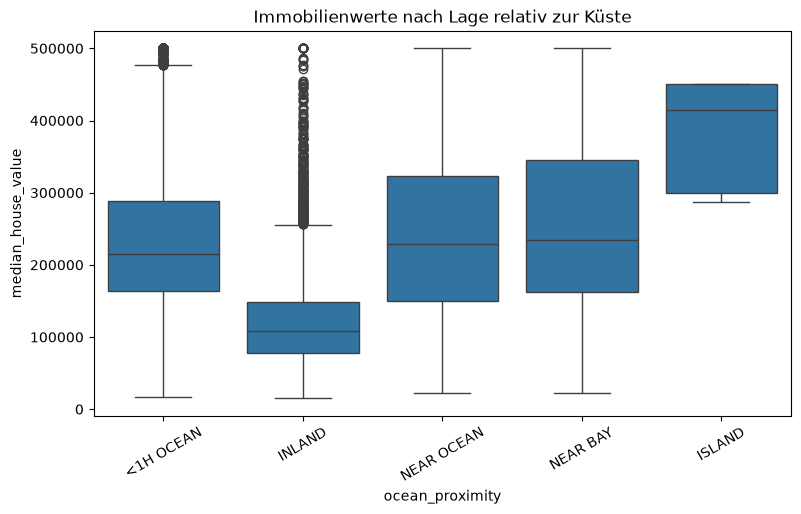

In [25]:
order = df_housing["ocean_proximity"].value_counts().index

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_housing,
    x="ocean_proximity",
    y="median_house_value",
    order=order
)
plt.xlabel("ocean_proximity")
plt.ylabel("median_house_value")
plt.title("Immobilienwerte nach Lage relativ zur Küste")
plt.xticks(rotation=30)
plt.show()

### Beobachtungen

Die Verteilungen unterscheiden sich zwischen den Kategorien sichtbar.

Bei der Interpretation ist jedoch Vorsicht nötig:

- Die Kategorien besitzen sehr unterschiedliche Fallzahlen.
- `ISLAND` umfasst nur sehr wenige Beobachtungen.
- Unterschiede zwischen den Gruppen sind zunächst **explorative Befunde**.

Die Grafik zeigt dennoch, dass die Lage relativ zur Küste für die weitere Analyse relevant sein könnte.


## 14. Pairplot: mehrere numerische Merkmale gemeinsam betrachten

Zum Abschluss der explorativen Zusammenhangsanalyse stellt ein Pairplot mehrere numerische Merkmale paarweise gegenüber.

Für eine übersichtliche und schnellere Darstellung wird hier nur eine **zufällige Teilmenge für die Grafik** verwendet.  
Der ursprüngliche DataFrame `df_housing` bleibt unverändert.


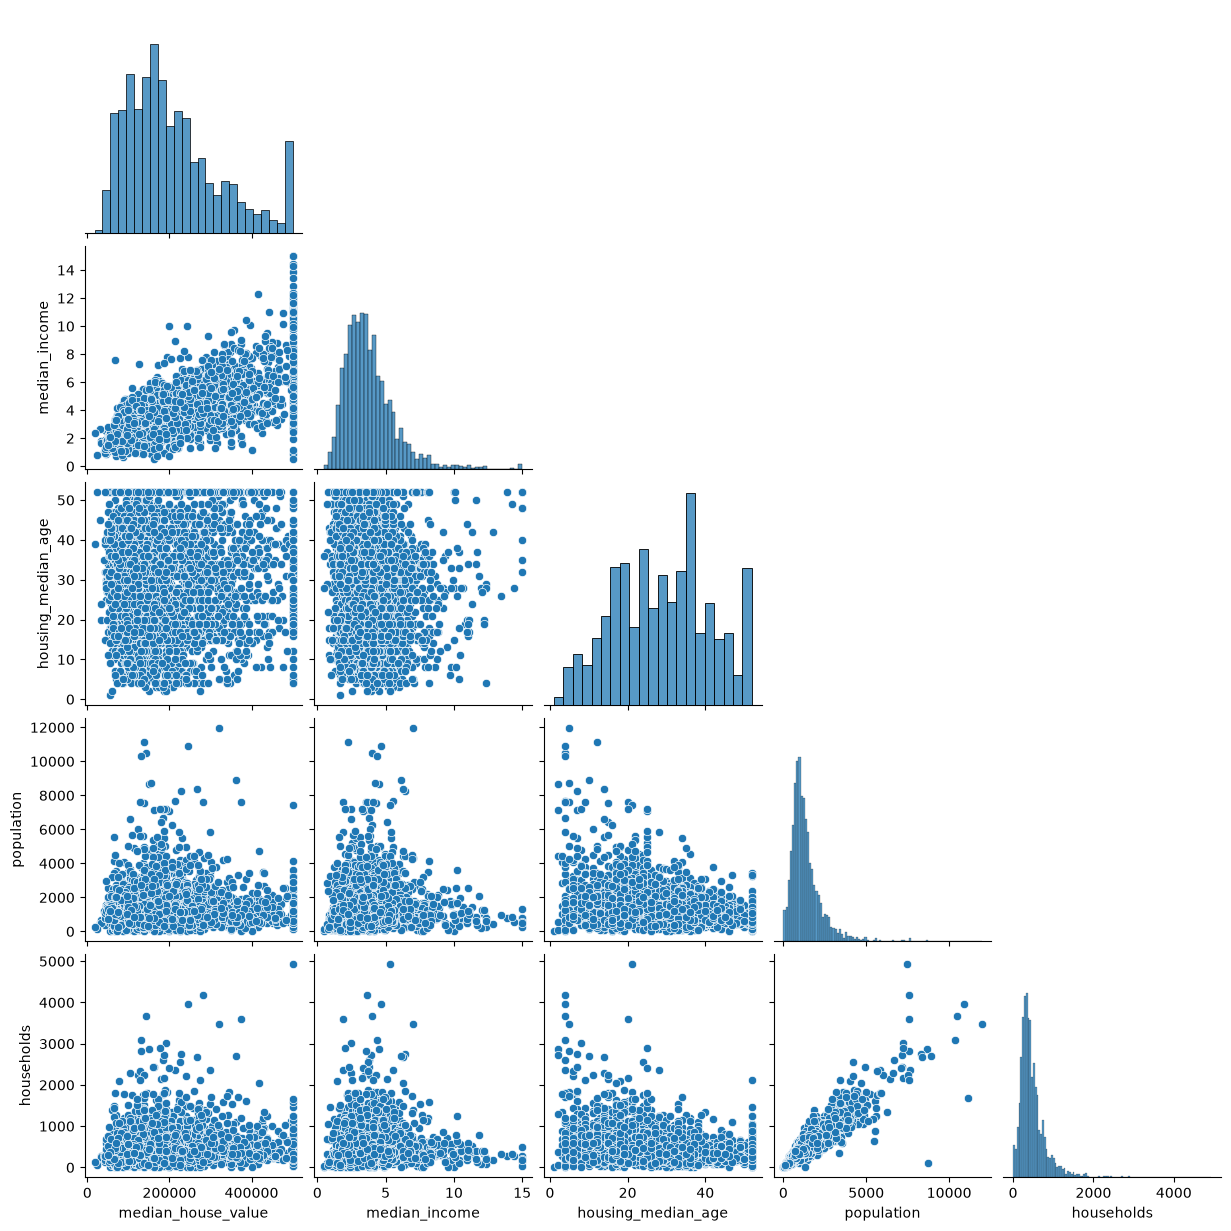

In [26]:
pair_columns = [
    "median_house_value",
    "median_income",
    "housing_median_age",
    "population",
    "households"
]

df_pair = df_housing[pair_columns].dropna()
df_pair_sample = df_pair.sample(
    n=min(3000, len(df_pair)),
    random_state=42
)

sns.pairplot(
    data=df_pair_sample,
    corner=True,
    diag_kind="hist"
)
plt.show()

### Was zeigt der Pairplot?

- Auf der Diagonalen stehen die Verteilungen der einzelnen Merkmale.
- Außerhalb der Diagonalen werden die Merkmale paarweise als Streudiagramme dargestellt.
- Besonders deutlich fällt der Zusammenhang zwischen `median_income` und `median_house_value` auf.
- Bei den Summenmerkmalen treten stark asymmetrische Verteilungen und sehr große Einzelwerte auf.

Der Pairplot dient als **Screening**. Er ersetzt nicht die fachliche Interpretation der einzelnen Zusammenhänge.


## 15. Zwischenfazit des Data Understanding

### Datenstruktur und Datenqualität

- Der Datensatz enthält 20.640 Block Groups und 10 Variablen.
- `ocean_proximity` ist kategorial, die übrigen Variablen sind numerisch gespeichert.
- Bei `total_bedrooms` fehlen 207 Werte.
- Begrenzungen sind unter anderem bei `housing_median_age`, `median_income` und `median_house_value` zu berücksichtigen.
- Die Summenmerkmale weisen große Wertebereiche und stark unterschiedliche Größenordnungen auf.

### Explorative inhaltliche Hinweise

- `median_income` zeigt einen deutlichen positiven Zusammenhang mit `median_house_value`.
- Die geografische Lage und `ocean_proximity` erscheinen ebenfalls relevant.
- Einzelne Summenmerkmale sind wegen unterschiedlich großer Block Groups nur eingeschränkt direkt vergleichbar.
- Kein einzelnes Merkmal erklärt die Unterschiede der Immobilienwerte vollständig.

### Konsequenzen für den nächsten CRISP-DM-Schritt

Das Data Understanding hat konkrete Punkte identifiziert, über die in der **Data Preparation** entschieden werden muss:

1. Wie werden die fehlenden Werte bei `total_bedrooms` behandelt?
2. Wie wird `ocean_proximity` für spätere Analysen aufbereitet?
3. Welche Merkmale sollen verwendet werden?
4. Sind Verhältnismerkmale wie Räume pro Haushalt oder Personen pro Haushalt fachlich sinnvoll?
5. Wie werden die bekannten Begrenzungen einzelner Variablen berücksichtigt?
6. Wann wird der Datensatz in Trainings- und Testdaten getrennt, damit spätere Aufbereitungsschritte keine Informationen aus Testdaten verwenden?

> **Data Understanding erkennt und beurteilt Auffälligkeiten – Data Preparation entscheidet, wie die Daten verändert werden.**


## Quellenhinweis

- Géron, Aurélien (2023): *Praxiseinstieg Machine Learning mit Scikit-Learn, Keras und TensorFlow*. 3., aktualisierte und erweiterte Auflage. O’Reilly, Kapitel 2.
- California Housing: Daten auf Basis des California Census 1990; verwendete Lehrdatensatzfassung nach Géron.
- Die Variablenübersicht und die fachliche Einordnung sind eine eigene Zusammenstellung auf Grundlage der Datensatzdokumentation und der Vorlesung.
